# GEDI + BIOMASS F155 — Our first comparison
## A simple English notebook using YOUR Parquet file

**The goal:** understand GEDI observations in your uploaded `gedi_gedidb_filtered_new (1).parquet` file, inspect their quality, and compare GEDI `rh_98` with the **same single ESA BIOMASS F155 height product** we studied before.

**Work one cell at a time.** Read the short explanation first, then run the Python code and see what happens. Every code section has comments.

**Scientific rule:** GEDI and BIOMASS do **not** measure exactly the same thing and do **not** have the same acquisition dates. A difference between them is not automatically an error.

**Files you need in ESA MAAP Jupyter:**

1. `gedi_gedidb_filtered_new (1).parquet` (your uploaded GEDI dataset).
2. Your previously saved **F155 Forest Height GeoTIFF** (from our earlier BIOMASS notebook).
3. Optionally, the **F155 Quality GeoTIFF**, if you also want to study the exploratory quality threshold.

No new BIOMASS products are searched here. No mosaics are created.

## 0 — What is in your GEDI file? (Checked from its Parquet metadata)

Your uploaded file is a **Parquet table**, not a raster image.

- **78,958 rows:** each row represents a GEDI observation/shot record.
- **171 columns:** the file contains many different GEDI variables. We will use only the few we need.
- **Latitude / longitude extent:** about **−0.329 to 0.561° N** and **12.293 to 13.007° E** — near our Ivindo study rectangle.
- **Time extent:** **21 April 2019 to 12 March 2025**.
- `rh_98`: GEDI relative height metric (metres). The metadata range is about **2.36–108.88 m**; an extreme value is not automatically reliable.
- `quality_flag`: the metadata indicate **1 for every row** in this particular file.
- `degrade_flag`: values range from **0 to 30**, so we still need to check and filter it.
- `sensitivity`: values are at least about **0.95** in this dataset.

These are properties of **this uploaded file**, not of every GEDI dataset. We will verify the observations with Python.

**Time warning:** our BIOMASS F155 product belongs to **6–18 March 2026**. GEDI in this file is older. Our initial comparison is exploratory because forest changes between years can affect the differences.

## 1 — What is GEDI? What does `rh_98` mean?

**GEDI** is a spaceborne **LiDAR** instrument. LiDAR sends laser pulses to Earth and records the light returned by surfaces at different heights.

- **BIOMASS**: radar-based estimate of forest height for each raster pixel.
- **GEDI**: laser-based measurements at footprints along orbital tracks.
- **A footprint** is the small area illuminated by one GEDI laser shot (approximately 25 m across).
- `rh_98` means **98% of the cumulative returned waveform energy lies below that relative height**, measured with respect to the estimated ground reference.

**Simple picture:** BIOMASS is like a grid of squares on a map. GEDI is like dots following lines through that grid.

**Important:** `rh_98` is a widely used *canopy height proxy*, but it is **not identical by definition** to the BIOMASS Forest Height parameter. This must be considered when we interpret the comparison.

## 2 — Import the tools

- `pandas` reads the Parquet table.
- `numpy` works with numerical values.
- `matplotlib` draws maps and plots.
- `rasterio` reads the BIOMASS GeoTIFF and finds which raster pixel contains each GEDI point.

**Run this in MAAP.** If you get a Parquet-engine error, the MAAP environment needs `pyarrow` installed (`%pip install pyarrow`, if package installation is permitted).

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import transform as transform_points
from rasterio.transform import rowcol
from rasterio.plot import plotting_extent

OUT = Path('GEDI_F155_comparison_results')
OUT.mkdir(exist_ok=True)

print('Output directory:', OUT.resolve())

Output directory: /data/experiment/my-private-storage/fd3243c3-ea7f-43a3-ab61-cf837c71a507/FORESTHEIGH/GEDI_F155_comparison_results


## 3 — Find YOUR Parquet file

The exact filename has spaces and parentheses. **Do not rename it in the code unless you renamed your actual file.**

Upload the Parquet file to the same working directory as this notebook on ESA MAAP. The `/mnt/data` fallback is only useful in some environments, including this chat's sandbox.

In [5]:
PARQUET_NAME = 'gedi_gedidb_filtered_new (1).parquet'

possible_files = [
    Path(PARQUET_NAME),
    Path('/mnt/data') / PARQUET_NAME,
]

GEDI_FILE = next((p for p in possible_files if p.exists()), None)

if GEDI_FILE is None:
    raise FileNotFoundError(
        'GEDI Parquet file not found. Upload it to the same directory as this notebook, '
        'or change PARQUET_NAME to its actual path.'
    )

print('Found GEDI file:', GEDI_FILE)
print('Size (MB):', round(GEDI_FILE.stat().st_size / 1e6, 1))

Found GEDI file: gedi_gedidb_filtered_new (1).parquet
Size (MB): 35.2


## 4 — Read only the columns we need

A Parquet table can have hundreds of columns. We do not need to load them all.

**Our main columns:**

- `latitude`, `longitude`: the point's location.
- `time`: when GEDI measured that point.
- `shot_number`: identifier of a GEDI laser shot.
- `rh_98`: GEDI's height-related measurement.
- `quality_flag`, `degrade_flag`, `sensitivity`: useful quality information.

Read the output of `head()` carefully: **each row is one point**, not a map pixel.

In [6]:
GEDI_COLUMNS = [
    'latitude', 'longitude', 'time', 'shot_number',
    'rh_98', 'quality_flag', 'degrade_flag', 'sensitivity'
]

# Read just the columns above from your uploaded Parquet file.
try:
    gedi = pd.read_parquet(GEDI_FILE, columns=GEDI_COLUMNS)
except ImportError as exc:
    raise ImportError(
        'Reading Parquet requires pyarrow or fastparquet. '
        'In MAAP, try %pip install pyarrow in a separate notebook cell.'
    ) from exc

print('Rows:', len(gedi))
print('Columns:', list(gedi.columns))
display(gedi.head())

# Convert time to a standard datetime representation (UTC).
gedi['time'] = pd.to_datetime(gedi['time'], utc=True, errors='coerce')
print('GEDI date range:', gedi['time'].min(), 'to', gedi['time'].max())

Rows: 78958
Columns: ['latitude', 'longitude', 'time', 'shot_number', 'rh_98', 'quality_flag', 'degrade_flag', 'sensitivity']


,latitude,longitude,time,shot_number,rh_98,quality_flag,degrade_flag,sensitivity
0,-0.276814,13.006859,2025-01-06,343810500200060234,20.330000,1,0,0.989127
1,-0.279766,13.004777,2025-01-06,343810500200060227,17.940001,1,0,0.992569
2,-0.288195,13.005702,2025-01-06,343810600200275290,30.459999,1,0,0.985495
3,-0.320693,12.982823,2025-01-06,343810600200275213,17.790001,1,0,0.990185
4,-0.050901,12.666646,2025-01-25,346710600200276268,43.139999,1,30,0.990932


GEDI date range: 2019-04-21 00:00:00+00:00 to 2025-03-12 00:00:00+00:00


## 5 — Check the quality information BEFORE filtering

A file called “filtered” may still contain records that fail some checks.

- `quality_flag == 1`: a GEDI L2A quality criterion.
- `degrade_flag == 0`: excludes observations marked as degraded.
- `sensitivity`: indicates how capable the waveform is of detecting the ground in a vegetated scene. Your file already has values ≥ approximately 0.95, but we still inspect them.

**We do not invent a new sensitivity threshold today.** Let's first use the existing quality/degrade information and the numerical values.

In [7]:
print('quality_flag counts:')
print(gedi['quality_flag'].value_counts(dropna=False).sort_index())

print('\ndegrade_flag counts:')
print(gedi['degrade_flag'].value_counts(dropna=False).sort_index())

print('\nsensitivity distribution:')
print(gedi['sensitivity'].describe())

print('\nGEDI RH98 distribution:')
print(gedi['rh_98'].describe())

quality_flag counts:
quality_flag
1    78958
Name: count, dtype: int64

degrade_flag counts:
degrade_flag
0     71939
30     7019
Name: count, dtype: int64

sensitivity distribution:
count    78958.000000
mean         0.985004
std          0.009712
min          0.950016
25%          0.983926
50%          0.988383
75%          0.990855
max          0.997555
Name: sensitivity, dtype: float64

GEDI RH98 distribution:
count    78958.000000
mean        33.708992
std          8.290102
min          2.360000
25%         28.889999
50%         34.009998
75%         38.660000
max        108.879997
Name: rh_98, dtype: float64


## 6 — Create a clean GEDI working table

We keep GEDI observations with:

1. Valid latitude, longitude and RH98 numbers.
2. A **positive** RH98 value.
3. `quality_flag == 1` and `degrade_flag == 0`.

**Why positive?** We are studying forest height; a non-positive RH98 cannot be a usable positive canopy-height estimate for this simple analysis. This is a practical first-pass filter, not a complete official GEDI quality-screening recipe.

We do **not** force a maximum height. We will inspect unusually high points separately rather than hiding them.

In [8]:
# Work on a copy, keeping your original table unchanged.
gedi_clean = gedi.copy()

for col in ['latitude', 'longitude', 'rh_98', 'sensitivity']:
    gedi_clean[col] = pd.to_numeric(gedi_clean[col], errors='coerce')

valid = (
    np.isfinite(gedi_clean['latitude']) &
    np.isfinite(gedi_clean['longitude']) &
    np.isfinite(gedi_clean['rh_98']) &
    gedi_clean['latitude'].between(-90, 90) &
    gedi_clean['longitude'].between(-180, 180) &
    (gedi_clean['rh_98'] > 0) &
    (gedi_clean['quality_flag'] == 1) &
    (gedi_clean['degrade_flag'] == 0)
)

gedi_clean = gedi_clean.loc[valid].copy()
print('GEDI rows before filtering:', len(gedi))
print('GEDI rows after filtering:', len(gedi_clean))
print('Retained (%):', round(100 * len(gedi_clean) / len(gedi), 2))

if gedi_clean.empty:
    raise ValueError('No GEDI rows passed the initial filters. Recheck the fields.')

GEDI rows before filtering: 78958
GEDI rows after filtering: 71939
Retained (%): 91.11


## 7 — Visualize GEDI: points on a map + height histogram

We want to understand where our GEDI observations are located, and whether their height distribution is sensible.

We are **not drawing a continuous map of the forest**. The dots show GEDI shot locations; empty spaces simply have no shot from this file.

The rectangle is the study **bounding box**, not the official boundary of Ivindo National Park.

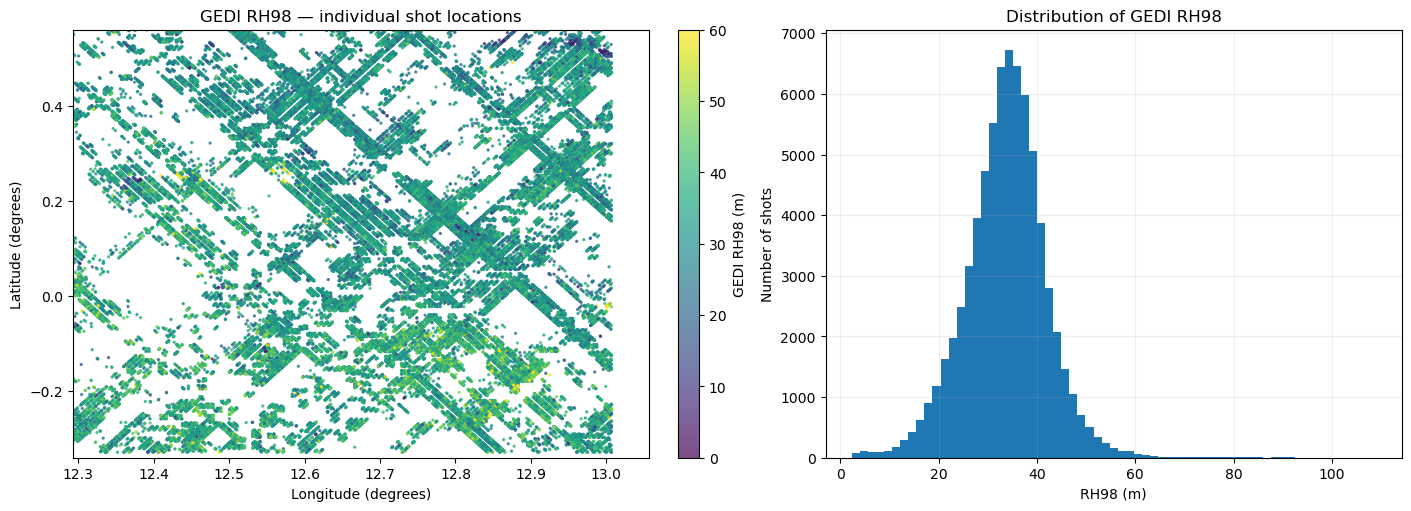

In [9]:
STUDY_BBOX = [12.29287, -0.34049, 13.05662, 0.55979]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

sc = axes[0].scatter(
    gedi_clean['longitude'], gedi_clean['latitude'],
    c=gedi_clean['rh_98'], s=2, alpha=0.7,
    cmap='viridis', vmin=0, vmax=60, rasterized=True
)
axes[0].set_xlim(STUDY_BBOX[0], STUDY_BBOX[2])
axes[0].set_ylim(STUDY_BBOX[1], STUDY_BBOX[3])
axes[0].set_title('GEDI RH98 — individual shot locations')
axes[0].set_xlabel('Longitude (degrees)')
axes[0].set_ylabel('Latitude (degrees)')
fig.colorbar(sc, ax=axes[0], label='GEDI RH98 (m)')

axes[1].hist(gedi_clean['rh_98'], bins=65)
axes[1].set_title('Distribution of GEDI RH98')
axes[1].set_xlabel('RH98 (m)')
axes[1].set_ylabel('Number of shots')
axes[1].grid(alpha=0.2)
plt.savefig(OUT / '01_GEDI_map_and_histogram.png', dpi=180)
plt.show()

## 8 — Check observation dates

GEDI measurements here are from **2019–2025**. Our BIOMASS F155 product covers **March 2026**.

A forest may have changed because of disturbances, recovery, or other processes. A difference between the two sensors may reflect both measurement differences **and time differences**.

**Important:** we must report the time mismatch in our future presentation.

GEDI shots by year:
year
2019    14914
2020    22711
2021    19383
2022    11254
2023     2869
2024      473
2025      335
Name: count, dtype: int64


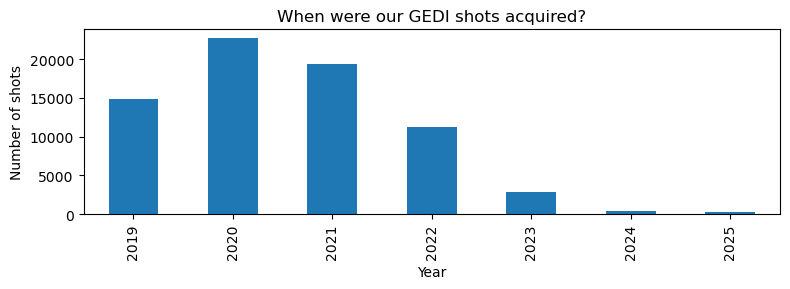

In [10]:
gedi_clean['year'] = gedi_clean['time'].dt.year
counts_by_year = gedi_clean['year'].value_counts(dropna=False).sort_index()
print('GEDI shots by year:')
print(counts_by_year)

counts_by_year.plot(kind='bar', figsize=(8, 3))
plt.title('When were our GEDI shots acquired?')
plt.xlabel('Year')
plt.ylabel('Number of shots')
plt.tight_layout()
plt.savefig(OUT / '02_GEDI_dates.png', dpi=180)
plt.show()

## 9 — Find the F155 raster that we already processed

Now we bring back the **one BIOMASS product F155** from our previous work.

The code looks in the two output folders used by our earlier BIOMASS notebooks. If you saved the TIFF elsewhere, change `F155_HEIGHT_FILE` yourself. **Do not accidentally select the multi-product `median_height.tif`: that would no longer be our single F155 analysis.**

If the quality TIFF exists, we will read it later too. If not, we can still perform the basic GEDI-vs-BIOMASS comparison.

In [11]:
F155_ID = (
    'BIO_FP_FH__L2A_20260306T172102_20260318T172131_'
    'T_G01_M02_C___T011_F155_02_DUFRGT'
)

height_candidates = [
    Path('F155_simple_analysis_results') / 'F155_original_height.tif',
    Path('ivindo_all_results') / 'individual_rasters' / f'{F155_ID}_FH.tif',
]
quality_candidates = [
    Path('F155_simple_analysis_results') / 'F155_quality.tif',
    Path('ivindo_all_results') / 'individual_rasters' / f'{F155_ID}_QUALITY.tif',
]

F155_HEIGHT_FILE = next((p for p in height_candidates if p.exists()), None)
F155_QUALITY_FILE = next((p for p in quality_candidates if p.exists()), None)

print('F155 height file:', F155_HEIGHT_FILE)
print('F155 quality file (optional):', F155_QUALITY_FILE)

# If F155_HEIGHT_FILE is None, STOP here and place the correct TIFF in one
# of the folders above (or change F155_HEIGHT_FILE to its real Path).
if F155_HEIGHT_FILE is None:
    raise FileNotFoundError(
        'The saved F155 Forest Height TIFF is missing. Run the save-TIFF '
        'step in your previous BIOMASS notebook, then come back here.'
    )

with rasterio.open(F155_HEIGHT_FILE) as src:
    print('CRS:', src.crs)
    print('Size:', src.width, 'x', src.height, 'pixels')
    print('Bounds:', src.bounds)
    print('NoData:', src.nodata)
    if src.crs is None:
        raise ValueError('F155 GeoTIFF has no CRS; do not match coordinates yet.')

F155 height file: F155_simple_analysis_results/F155_original_height.tif
F155 quality file (optional): F155_simple_analysis_results/F155_quality.tif
CRS: EPSG:4326
Size: 906 x 1081 pixels
Bounds: BoundingBox(left=12.301945686340332, bottom=-0.3406890034675598, right=13.057106971740723, top=0.5601434707641602)
NoData: -9999.0


## 10 — The most important spatial step: match a GEDI dot with a BIOMASS pixel

**Question:** a GEDI shot is at latitude −0.1°, longitude 12.7°. Which number in our BIOMASS GeoTIFF corresponds to that position?

Every GeoTIFF has a **coordinate reference system (CRS)** and a transform that tells us where its pixels are located.

The next function:

1. Takes GEDI latitude/longitude.
2. Changes coordinates to the GeoTIFF's CRS if needed.
3. Finds the pixel containing each point.
4. Reads its numerical value.
5. Returns `NaN` for points outside the image or on missing-value pixels.

**This is a point-to-pixel comparison, not a perfect footprint-to-footprint match.** GEDI has a small footprint and BIOMASS may have a much larger effective spatial support. We will discuss this limitation before claiming accuracy.

In [12]:
def sample_geotiff_at_gedi_points(tif_path, longitude, latitude):
    """Read the raster value under each GEDI point, preserving the point order."""
    longitude = np.asarray(longitude, dtype=float)
    latitude = np.asarray(latitude, dtype=float)
    result = np.full(len(longitude), np.nan, dtype=float)

    with rasterio.open(tif_path) as src:
        if src.crs is None:
            raise ValueError(f'Raster has no CRS: {tif_path}')

        # GEDI uses lon/lat in WGS84. Convert to the raster CRS if necessary.
        xs, ys = transform_points('EPSG:4326', src.crs, longitude.tolist(), latitude.tolist())

        # Convert map coordinates into pixel row and column numbers.
        rows, cols = rowcol(src.transform, xs, ys)
        rows = np.asarray(rows, dtype=int)
        cols = np.asarray(cols, dtype=int)

        # Avoid reading outside raster boundaries.
        inside = (
            (rows >= 0) & (rows < src.height) &
            (cols >= 0) & (cols < src.width)
        )
        if inside.any():
            raster = src.read(1, masked=True)
            values = raster[rows[inside], cols[inside]]
            result[inside] = np.ma.filled(values.astype(float), np.nan)

    return result

# One GEDI point becomes one matched BIOMASS pixel value.
matched = gedi_clean.copy()
matched['biomass_height_m'] = sample_geotiff_at_gedi_points(
    F155_HEIGHT_FILE,
    matched['longitude'],
    matched['latitude']
)

print('Filtered GEDI shots:', len(matched))
print('Points with a numerical F155 height:', matched['biomass_height_m'].notna().sum())

# Keep only GEDI points for which F155 contains numerical height data.
paired = matched.loc[np.isfinite(matched['biomass_height_m'])].copy()
print('Matched GEDI–BIOMASS pairs:', len(paired))

if paired.empty:
    raise ValueError('No GEDI points matched F155 valid pixels. Check raster bounds and CRS.')

display(paired[['latitude', 'longitude', 'time', 'rh_98', 'biomass_height_m']].head())

Filtered GEDI shots: 71939
Points with a numerical F155 height: 54949
Matched GEDI–BIOMASS pairs: 54949


,latitude,longitude,time,rh_98,biomass_height_m
13,-0.237168,12.677259,2025-02-01 00:00:00+00:00,26.010000,15.320030
14,-0.325722,12.733047,2025-02-01 00:00:00+00:00,13.320000,36.310799
15,-0.172139,12.608650,2025-02-01 00:00:00+00:00,31.080000,33.044079
16,-0.170044,12.607167,2025-02-01 00:00:00+00:00,40.680000,30.231480
17,-0.170631,12.614074,2025-02-01 00:00:00+00:00,39.220001,25.838974


## 11 — Draw GEDI points over the original BIOMASS F155 image

This figure is **not a new mosaic**. It is our single F155 height raster with a sample of GEDI positions on top.

We plot the dots in the same coordinate system as the raster, so they appear in the right places.

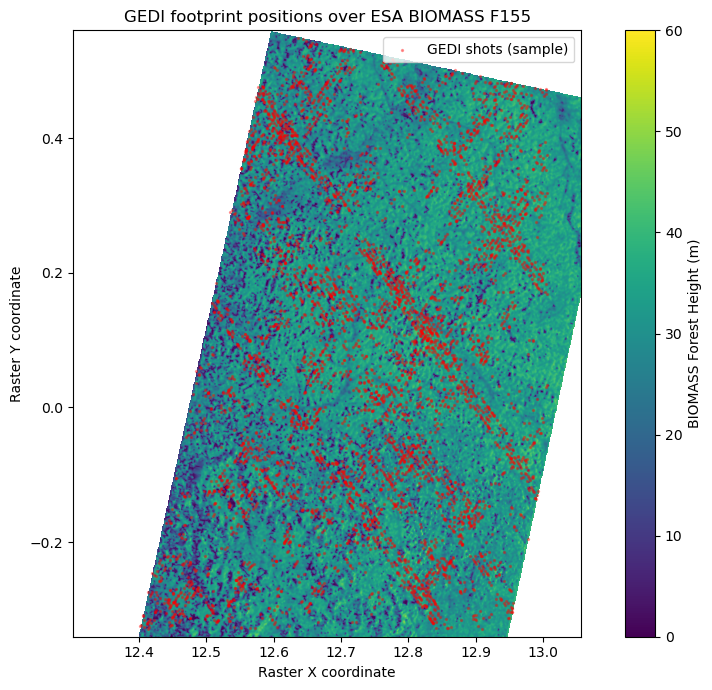

In [13]:
# For visualization only, use a subset if there are many points.
plot_points = paired.sample(n=min(len(paired), 5000), random_state=42)

with rasterio.open(F155_HEIGHT_FILE) as src:
    raster = src.read(1, masked=True)
    extent = plotting_extent(src)
    px, py = transform_points(
        'EPSG:4326', src.crs,
        plot_points['longitude'].tolist(),
        plot_points['latitude'].tolist()
    )

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(raster, extent=extent, origin='upper', cmap='viridis', vmin=0, vmax=60)
ax.scatter(px, py, s=2, c='red', alpha=0.35, label='GEDI shots (sample)')
ax.set_title('GEDI footprint positions over ESA BIOMASS F155')
ax.set_xlabel('Raster X coordinate')
ax.set_ylabel('Raster Y coordinate')
ax.legend(loc='upper right')
fig.colorbar(im, ax=ax, label='BIOMASS Forest Height (m)')
plt.tight_layout()
plt.savefig(OUT / '03_GEDI_over_BIOMASS_F155.png', dpi=180)
plt.show()

BIOMASS CRS: EPSG:4326
BIOMASS bounds: BoundingBox(left=12.301945686340332, bottom=-0.3406890034675598, right=13.057106971740723, top=0.5601434707641602)


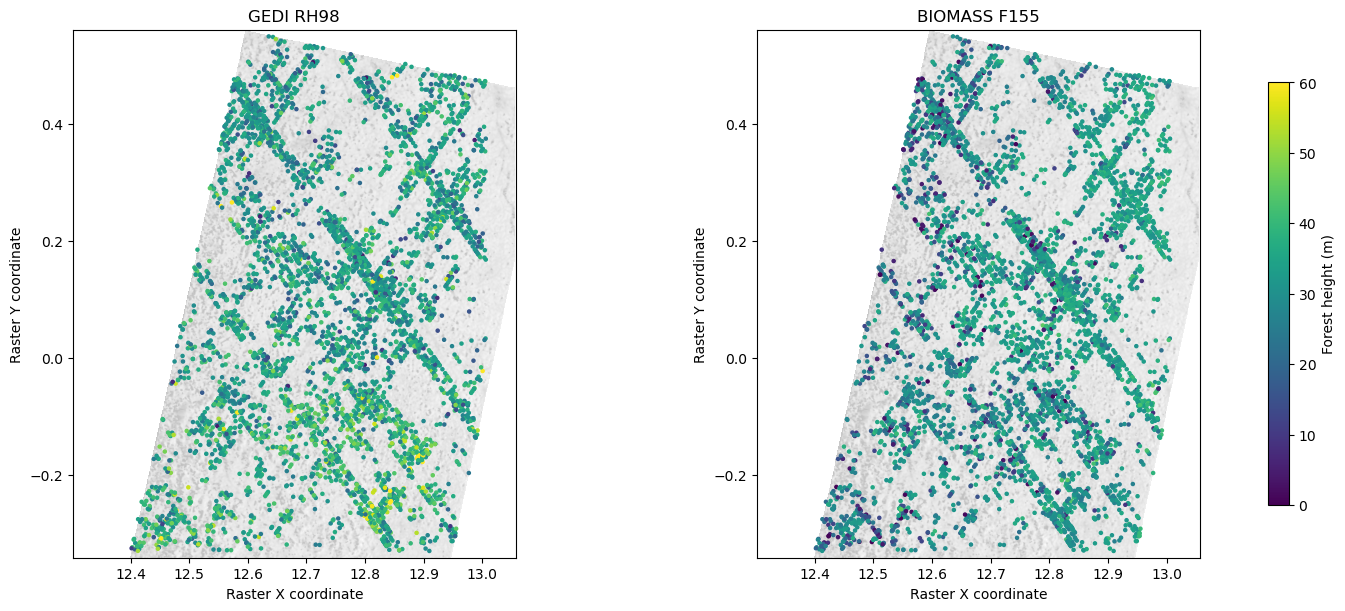

In [21]:

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import transform as transform_points
from rasterio.plot import plotting_extent

# Select the SAME GEDI observations for both maps
points = paired.sample(
    n=min(5000, len(paired)),
    random_state=42
)

with rasterio.open(F155_HEIGHT_FILE) as src:

    print("BIOMASS CRS:", src.crs)
    print("BIOMASS bounds:", src.bounds)

    # Convert GEDI coordinates to the raster CRS
    xs, ys = transform_points(
        "EPSG:4326",
        src.crs,
        points["longitude"].tolist(),
        points["latitude"].tolist()
    )

    # Read BIOMASS raster for background
    raster = src.read(1, masked=True)
    extent = plotting_extent(src)

fig, axes = plt.subplots(
    1, 2, figsize=(15, 6),
    constrained_layout=True
)

# Both maps show exactly the same geographic positions
for ax in axes:

    ax.imshow(
        raster,
        extent=extent,
        origin="upper",
        cmap="gray",
        alpha=0.25
    )

    ax.set_xlabel("Raster X coordinate")
    ax.set_ylabel("Raster Y coordinate")

# Map 1: GEDI heights
im1 = axes[0].scatter(
    xs, ys,
    c=points["rh_98"],
    cmap="viridis",
    vmin=0, vmax=60,
    s=5
)

axes[0].set_title("GEDI RH98")

# Map 2: BIOMASS heights at SAME positions
im2 = axes[1].scatter(
    xs, ys,
    c=points["biomass_height_m"],
    cmap="viridis",
    vmin=0, vmax=60,
    s=5
)

axes[1].set_title("BIOMASS F155")

fig.colorbar(
    im2, ax=axes,
    label="Forest height (m)",
    shrink=0.8
)

plt.show()


In [22]:
# Verify the extracted BIOMASS values independently

with rasterio.open(F155_HEIGHT_FILE) as src:

    direct_values = []

    for value in src.sample(zip(xs, ys), masked=True):
        direct_values.append(
            np.nan if np.ma.is_masked(value[0])
            else float(value[0])
        )

direct_values = np.array(direct_values)

previous_values = points["biomass_height_m"].to_numpy()

difference = np.abs(direct_values - previous_values)

print("Maximum extraction difference:",
      np.nanmax(difference), "m")

Maximum extraction difference: 0.0 m


In [23]:
import numpy as np
import rasterio
from rasterio.warp import transform

with rasterio.open(F155_HEIGHT_FILE) as src:

    xs, ys = transform(
        "EPSG:4326",
        src.crs,
        paired["longitude"].tolist(),
        paired["latitude"].tolist()
    )

    rows, cols = rasterio.transform.rowcol(
        src.transform, xs, ys
    )

    print("BIOMASS CRS:", src.crs)
    print("BIOMASS pixel size:", src.res)

# Assign every GEDI observation to a BIOMASS pixel
data = paired.copy()

data["row"] = rows
data["col"] = cols

# Group GEDI observations by BIOMASS pixel
pixel_data = data.groupby(["row", "col"]).agg(
    GEDI_height=("rh_98", "median"),
    BIOMASS_height=("biomass_height_m", "first"),
    N_GEDI=("rh_98", "size")
).reset_index()

# Examine different minimum numbers of GEDI observations
for minimum in [1, 2, 3]:

    subset = pixel_data[
        pixel_data["N_GEDI"] >= minimum
    ]

    print(f"\nMinimum GEDI observations: {minimum}")
    print("BIOMASS pixels:", len(subset))

    if len(subset) >= 2:
        print(
            "Pearson correlation:",
            round(
                subset["GEDI_height"].corr(
                    subset["BIOMASS_height"]
                ), 3
            )
        )

BIOMASS CRS: EPSG:4326
BIOMASS pixel size: (0.0008335113525390625, 0.0008333325386047363)

Minimum GEDI observations: 1
BIOMASS pixels: 39109
Pearson correlation: -0.038

Minimum GEDI observations: 2
BIOMASS pixels: 14572
Pearson correlation: -0.044

Minimum GEDI observations: 3
BIOMASS pixels: 1036
Pearson correlation: -0.064



 Quality <= 20%


,N,GEDI_mean,BIOMASS_mean,Bias,MAE
GEDI_class,,,,,
0-20,2499,15.730000,31.09,-15.35,15.69
20-30,12019,26.080000,30.97,-4.88,6.77
30-40,25287,34.939999,31.37,3.58,5.38
40-50,8241,43.400002,30.65,12.75,12.77
>50,1251,55.770000,29.72,26.06,26.06



 Quality > 20%


,N,GEDI_mean,BIOMASS_mean,Bias,MAE
GEDI_class,,,,,
0-20,266,15.510000,12.64,2.87,7.79
20-30,1166,26.000000,12.36,13.64,13.92
30-40,2927,35.180000,11.95,23.23,23.23
40-50,1169,43.529999,11.83,31.70,31.70
>50,124,55.020000,10.81,44.21,44.21


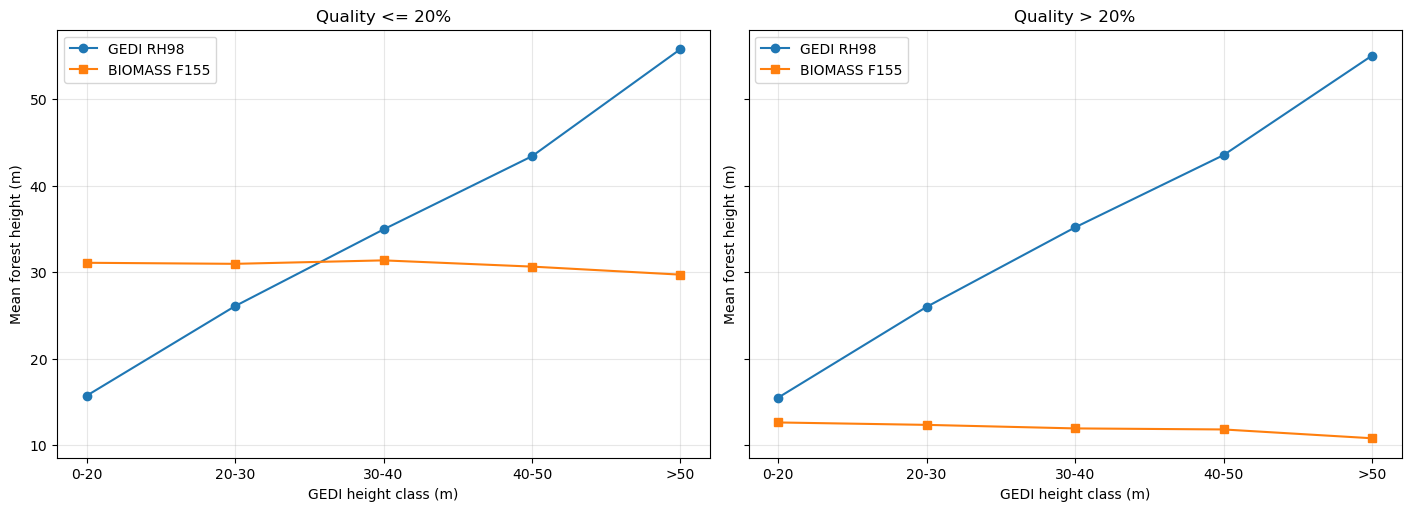

In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Prepare the data
data = paired.copy()

# Keep observations with numerical values
data = data.dropna(subset=[
    "rh_98",
    "biomass_height_m",
    "biomass_quality"
])

# 2. Divide GEDI heights into classes
bins = [0, 20, 30, 40, 50, np.inf]
labels = ["0-20", "20-30", "30-40", "40-50", ">50"]

data["GEDI_class"] = pd.cut(
    data["rh_98"],
    bins=bins,
    labels=labels,
    right=False
)

# 3. Calculate GEDI - BIOMASS differences
data["difference"] = (
    data["rh_98"] - data["biomass_height_m"]
)

data["absolute_error"] = np.abs(data["difference"])

# 4. Compare low-bias and high-bias pixels
groups = {
    "Quality <= 20%": data[data["biomass_quality"] <= 20],
    "Quality > 20%": data[data["biomass_quality"] > 20]
}

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5),
    sharey=True,
    constrained_layout=True
)

for ax, (name, subset) in zip(axes, groups.items()):

    # Calculate statistics for each GEDI height class
    stats = subset.groupby(
        "GEDI_class", observed=True
    ).agg(
        N=("rh_98", "size"),
        GEDI_mean=("rh_98", "mean"),
        BIOMASS_mean=("biomass_height_m", "mean"),
        Bias=("difference", "mean"),
        MAE=("absolute_error", "mean")
    ).reindex(labels)

    print("\n", name)
    display(stats.round(2))

    # Compare average heights
    x = np.arange(len(labels))

    ax.plot(
        x, stats["GEDI_mean"],
        "o-", label="GEDI RH98"
    )

    ax.plot(
        x, stats["BIOMASS_mean"],
        "s-", label="BIOMASS F155"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_xlabel("GEDI height class (m)")
    ax.set_ylabel("Mean forest height (m)")
    ax.set_title(name)
    ax.grid(alpha=0.3)
    ax.legend()

plt.show()


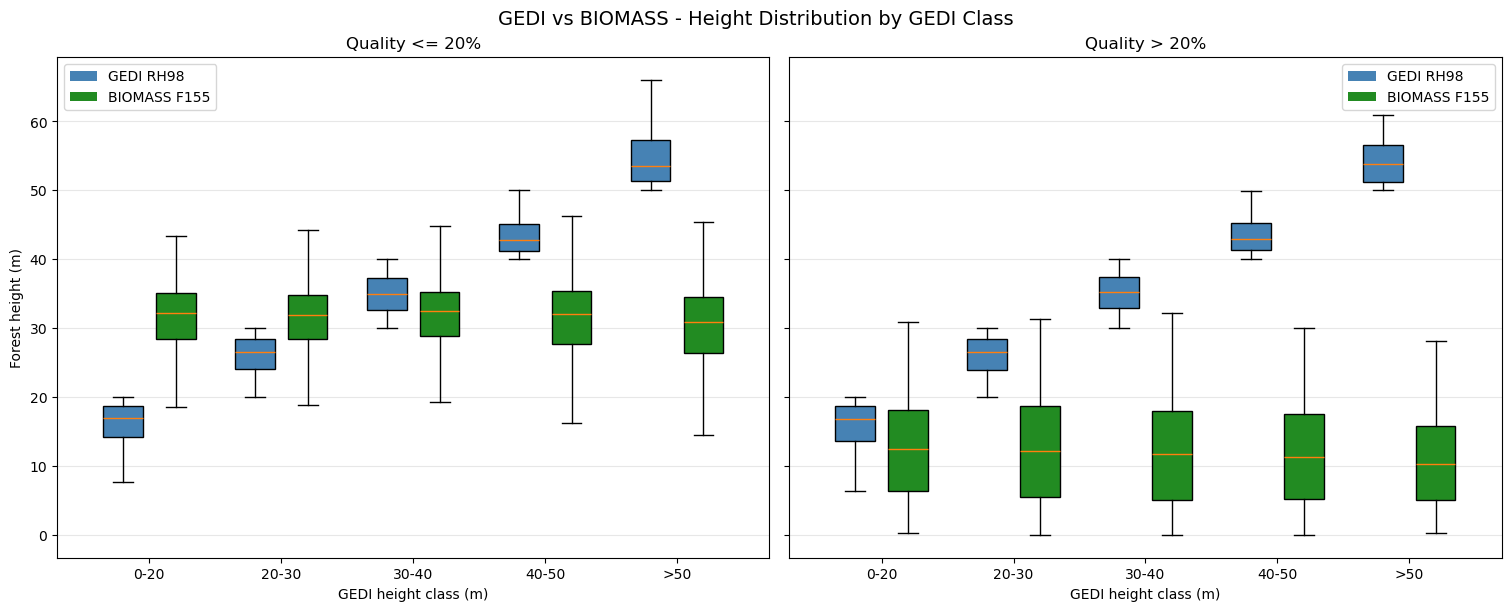

In [25]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Prepare data
data = paired.copy()

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=[
    "rh_98",
    "biomass_height_m",
    "biomass_quality"
])

# Define GEDI height classes
bins = [0, 20, 30, 40, 50, np.inf]
labels = ["0-20", "20-30", "30-40", "40-50", ">50"]

data["GEDI_class"] = pd.cut(
    data["rh_98"],
    bins=bins,
    labels=labels,
    right=False
)

# Separate by BIOMASS inversion bias
groups = {
    "Quality <= 20%": data[data["biomass_quality"] <= 20],
    "Quality > 20%": data[data["biomass_quality"] > 20]
}

fig, axes = plt.subplots(
    1, 2, figsize=(15, 6),
    sharey=True,
    constrained_layout=True
)

for ax, (title, subset) in zip(axes, groups.items()):

    for i, label in enumerate(labels):

        group = subset[subset["GEDI_class"] == label]

        if group.empty:
            continue

        # GEDI height distribution
        gedi_values = group["rh_98"].to_numpy()

        # BIOMASS height distribution
        biomass_values = group["biomass_height_m"].to_numpy()

        # GEDI box plot
        bp1 = ax.boxplot(
            gedi_values,
            positions=[i + 0.8],
            widths=0.3,
            patch_artist=True,
            showfliers=False
        )

        # BIOMASS box plot
        bp2 = ax.boxplot(
            biomass_values,
            positions=[i + 1.2],
            widths=0.3,
            patch_artist=True,
            showfliers=False
        )

        # Colors
        for box in bp1["boxes"]:
            box.set_facecolor("steelblue")

        for box in bp2["boxes"]:
            box.set_facecolor("forestgreen")

    ax.set_xticks(range(1, len(labels) + 1))
    ax.set_xticklabels(labels)

    ax.set_xlabel("GEDI height class (m)")
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)

    ax.legend(handles=[
        Patch(facecolor="steelblue", label="GEDI RH98"),
        Patch(facecolor="forestgreen", label="BIOMASS F155")
    ])

axes[0].set_ylabel("Forest height (m)")

plt.suptitle(
    "GEDI vs BIOMASS - Height Distribution by GEDI Class",
    fontsize=14
)

plt.show()


## 12 — Compare GEDI RH98 and BIOMASS Forest Height

**One dot on the scatter plot = one GEDI observation paired with its BIOMASS pixel estimate.**

- X-axis = BIOMASS forest height (m).
- Y-axis = GEDI RH98 (m).
- The diagonal line `y = x` means **exact agreement** between the two numbers.

If the points are scattered far from the line, agreement is poorer. But remember **the sensors, time periods, and spatial supports differ**.

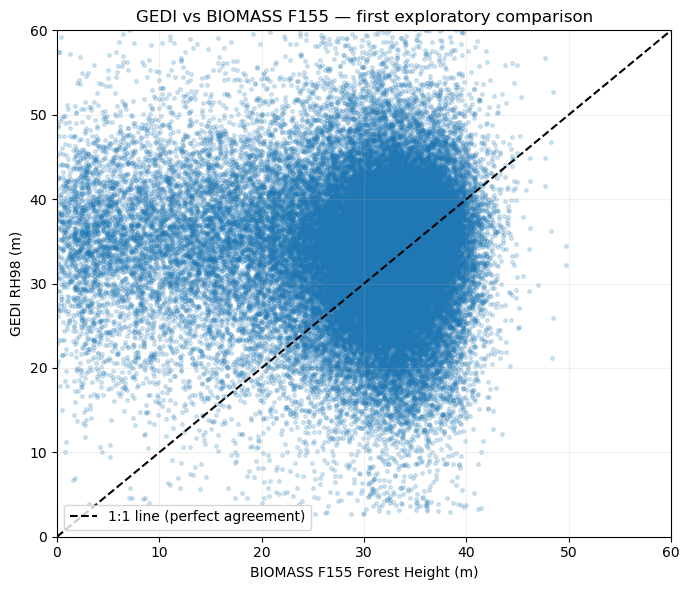

In [14]:
x = paired['biomass_height_m'].to_numpy(float)
y = paired['rh_98'].to_numpy(float)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(x, y, s=7, alpha=0.18, rasterized=True)

limit = max(60, float(np.percentile(np.concatenate([x, y]), 99)))
ax.plot([0, limit], [0, limit], 'k--', label='1:1 line (perfect agreement)')
ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.set_xlabel('BIOMASS F155 Forest Height (m)')
ax.set_ylabel('GEDI RH98 (m)')
ax.set_title('GEDI vs BIOMASS F155 — first exploratory comparison')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUT / '04_GEDI_vs_BIOMASS_scatter.png', dpi=180)
plt.show()

## 13 — Calculate the agreement statistics (in plain English)

We define the difference as:

**difference = GEDI RH98 − BIOMASS height**.

- **Bias:** the average signed difference. Positive bias means GEDI tends to be higher in this matched sample.
- **MAE (Mean Absolute Error):** the average *size* of the differences, ignoring their sign.
- **RMSE (Root Mean Square Error):** similar to MAE, but large differences count more.
- **Pearson correlation (r):** describes how strongly heights move up/down together; high correlation does not guarantee small differences.

These metrics describe **agreement**, not the independently verified error of BIOMASS, because GEDI is not an identical ground-truth measurement and dates differ.

In [15]:
def agreement_metrics(data):
    """GEDI minus BIOMASS; output a simple dictionary."""
    x = data['biomass_height_m'].to_numpy(dtype=float)
    y = data['rh_98'].to_numpy(dtype=float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]

    if len(x) == 0:
        return {'N': 0, 'Bias (m)': np.nan, 'MAE (m)': np.nan,
                'RMSE (m)': np.nan, 'Pearson r': np.nan}

    diff = y - x
    r = np.corrcoef(x, y)[0, 1] if len(x) > 1 and np.std(x) > 0 and np.std(y) > 0 else np.nan
    return {
        'N': len(x),
        'Bias (m)': float(np.mean(diff)),
        'MAE (m)': float(np.mean(np.abs(diff))),
        'RMSE (m)': float(np.sqrt(np.mean(diff**2))),
        'Pearson r': float(r),
    }

metrics_original = agreement_metrics(paired)
print('Initial GEDI vs F155 agreement (NOT a final accuracy validation):')
for k, v in metrics_original.items():
    print(k + ':', round(v, 3) if isinstance(v, float) else v)

Initial GEDI vs F155 agreement (NOT a final accuracy validation):
N: 54949
Bias (m): 4.701
MAE (m): 9.526
RMSE (m): 13.033
Pearson r: -0.036


## 14 — Optional: examine the F155 quality/bias layer (our previous experiment)

Earlier, we tried an **exploratory** filter where the BIOMASS quality value is `≤ 20`. This changed the average height because many excluded pixels had low estimated heights.

Now we can ask a better question: **among GEDI-matched locations, does the subset with lower BIOMASS quality/bias values show different agreement?**

**Fair interpretation:** the filtered group contains different points. Compare its metrics, but do **not** claim the filter made the heights more accurate. We have selected a different sample.

This cell is optional: it runs only if we have the F155 quality TIFF.

In [16]:
if F155_QUALITY_FILE is None:
    print('Quality GeoTIFF not found — skipping the exploratory BIOMASS quality comparison.')
else:
    paired['biomass_quality'] = sample_geotiff_at_gedi_points(
        F155_QUALITY_FILE,
        paired['longitude'], paired['latitude']
    )

    # IMPORTANT: threshold 20 is exploratory, NOT an official ESA rule.
    q_ok = np.isfinite(paired['biomass_quality'])
    q_le_20 = q_ok & (paired['biomass_quality'] <= 20)
    q_gt_20 = q_ok & (paired['biomass_quality'] > 20)

    rows = [
        {'Group': 'All pairs with quality value', **agreement_metrics(paired.loc[q_ok])},
        {'Group': 'Quality <= 20 (exploratory)', **agreement_metrics(paired.loc[q_le_20])},
        {'Group': 'Quality > 20', **agreement_metrics(paired.loc[q_gt_20])}
    ]

    comparison = pd.DataFrame(rows).set_index('Group')
    display(comparison.round(3))
    comparison.to_csv(OUT / 'GEDI_F155_quality_groups.csv')

    print('Do not interpret an improvement in metrics as proof that the filter fixes the estimates.')

,N,Bias (m),MAE (m),RMSE (m),Pearson r
Group,,,,,
All pairs with quality value,54949,4.701,9.526,13.033,-0.036
Quality <= 20 (exploratory),49297,2.660,8.004,10.792,-0.021
Quality > 20,5652,22.503,22.794,25.209,-0.039


Do not interpret an improvement in metrics as proof that the filter fixes the estimates.


In [18]:
print("HEIGHT COMPARISON BY QUALITY GROUP")

for name, mask in [
    ("Quality <= 20", q_le_20),
    ("Quality > 20", q_gt_20)
]:
    group = paired.loc[mask]

    print("\n", name)
    print("Number of pairs:", len(group))

    print(
        "Mean GEDI RH98:",
        round(group["rh_98"].mean(), 2), "m"
    )

    print(
        "Mean BIOMASS height:",
        round(group["biomass_height_m"].mean(), 2), "m"
    )

    print(
        "Median GEDI RH98:",
        round(group["rh_98"].median(), 2), "m"
    )

    print(
        "Median BIOMASS height:",
        round(group["biomass_height_m"].median(), 2), "m"
    )

HEIGHT COMPARISON BY QUALITY GROUP

 Quality <= 20
Number of pairs: 49297
Mean GEDI RH98: 33.75 m
Mean BIOMASS height: 31.09 m
Median GEDI RH98: 34.02 m
Median BIOMASS height: 32.21 m

 Quality > 20
Number of pairs: 5652
Mean GEDI RH98: 34.52 m
Mean BIOMASS height: 12.02 m
Median GEDI RH98: 35.06 m
Median BIOMASS height: 11.67 m


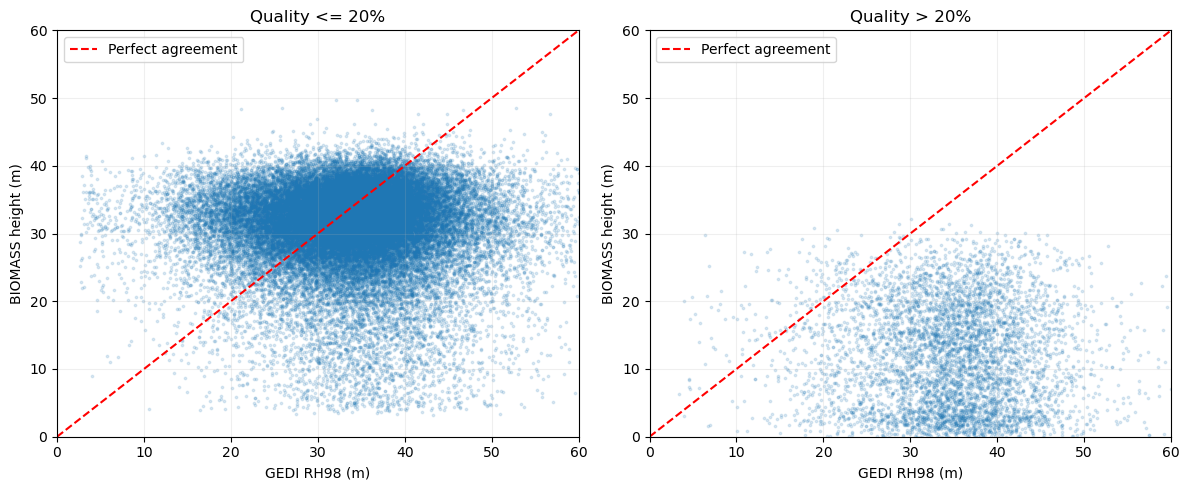

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

groups = [
    ("Quality <= 20%", q_le_20),
    ("Quality > 20%", q_gt_20)
]

for ax, (title, mask) in zip(axes, groups):

    data = paired.loc[mask]

    ax.scatter(
        data["rh_98"],
        data["biomass_height_m"],
        s=3,
        alpha=0.15
    )

    # Perfect agreement line
    ax.plot(
        [0, 60], [0, 60],
        "r--",
        label="Perfect agreement"
    )

    ax.set_xlim(0, 60)
    ax.set_ylim(0, 60)

    ax.set_xlabel("GEDI RH98 (m)")
    ax.set_ylabel("BIOMASS height (m)")
    ax.set_title(title)

    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Number of grid cells: 2386
Spatial correlation: -0.087


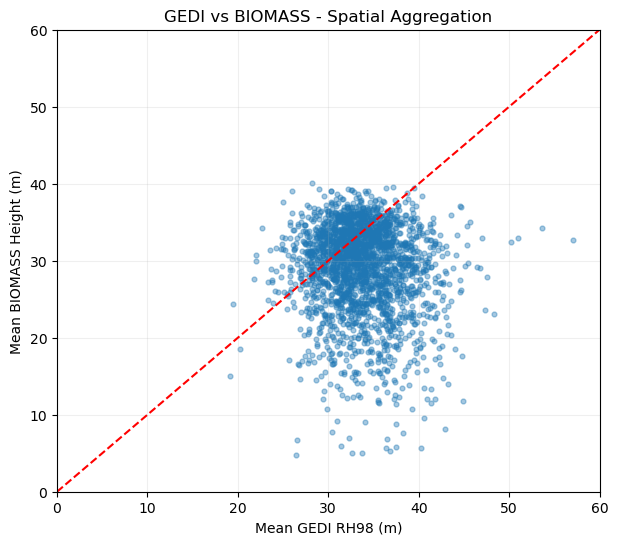

In [20]:
# Approximate 1 km grid near the equator
grid_size = 0.01  # degrees, approximately 1.1 km

data = paired.copy()

# Assign each observation to a geographical cell
data["grid_x"] = np.floor(data["longitude"] / grid_size)
data["grid_y"] = np.floor(data["latitude"] / grid_size)

# Calculate mean height for each cell
grid = data.groupby(["grid_x", "grid_y"]).agg(
    GEDI_mean=("rh_98", "mean"),
    BIOMASS_mean=("biomass_height_m", "mean"),
    N=("rh_98", "size")
).reset_index()

# Keep cells containing at least 5 GEDI observations
grid = grid[grid["N"] >= 5]

print("Number of grid cells:", len(grid))

if len(grid) >= 2:
    print(
        "Spatial correlation:",
        round(grid["GEDI_mean"].corr(grid["BIOMASS_mean"]), 3)
    )

    plt.figure(figsize=(7, 6))

    plt.scatter(
        grid["GEDI_mean"],
        grid["BIOMASS_mean"],
        alpha=0.4,
        s=12
    )

    plt.plot([0, 60], [0, 60], "r--")

    plt.xlabel("Mean GEDI RH98 (m)")
    plt.ylabel("Mean BIOMASS Height (m)")
    plt.title("GEDI vs BIOMASS - Spatial Aggregation")
    plt.xlim(0, 60)
    plt.ylim(0, 60)
    plt.grid(alpha=0.2)
    plt.show()
else:
    print("Not enough grid cells for correlation.")

## 15 — Save the matched observations for the next work session

Save the matched data as **CSV**, so you can reopen it without rerunning all steps. Each row contains GEDI position, date, RH98, and its sampled F155 height.

We also save simple statistics. The original uploaded GEDI Parquet is **never overwritten**.

In [17]:
csv_path = OUT / 'GEDI_F155_matched_shots.csv'
paired.to_csv(csv_path, index=False)

summary_path = OUT / 'GEDI_F155_initial_metrics.csv'
pd.DataFrame([metrics_original]).to_csv(summary_path, index=False)

print('Saved matched points:', csv_path.resolve())
print('Saved statistics:', summary_path.resolve())
print('Remember to keep the original GEDI Parquet and F155 GeoTIFFs as well.')

Saved matched points: /data/experiment/my-private-storage/fd3243c3-ea7f-43a3-ab61-cf837c71a507/FORESTHEIGH/GEDI_F155_comparison_results/GEDI_F155_matched_shots.csv
Saved statistics: /data/experiment/my-private-storage/fd3243c3-ea7f-43a3-ab61-cf837c71a507/FORESTHEIGH/GEDI_F155_comparison_results/GEDI_F155_initial_metrics.csv
Remember to keep the original GEDI Parquet and F155 GeoTIFFs as well.


## 16 — What we have learned (short notes you can write yourself)

1. **GEDI is a LiDAR instrument.** Each observation has a geographic location and a relative-height metric (`rh_98`).
2. **BIOMASS F155 is a georeferenced raster.** Each valid pixel contains a radar-based estimated forest height.
3. **We selected valid GEDI observations** using `quality_flag`, `degrade_flag` and checks on coordinates/RH98.
4. **We matched points to pixels:** for each GEDI location, we read the BIOMASS F155 pixel value.
5. **We compared the numbers** with a scatter plot, bias, MAE, RMSE and correlation.
6. **We must be cautious:** GEDI measurements in this file date from 2019–2025, while F155 is from 2026; GEDI footprints and BIOMASS pixels also have different spatial supports.
7. **We did not change BIOMASS heights.** A quality threshold only selects a subset of observations.

**Not done yet:** a full validation with spatial-footprint averaging, dates matched as closely as possible, robust uncertainty analysis and defensible quality criteria. Today's goal is to understand the data and make a correct *first* comparison.

### Quick self-test

- Why doesn't a GEDI map have a value everywhere?
- If GEDI = 35 m and BIOMASS = 30 m, what is our `GEDI − BIOMASS` difference?
- Why does a good correlation not imply a small RMSE?
- Why might GEDI from 2019 and BIOMASS from 2026 disagree even if both instruments work correctly?